# Lab 04: Fine-Tuning an LLM using LoRA / QLoRA
**PUSL 3205 – Large Language Models and Generative AI**

**K.L.D.N.H. Gunathilaka (35167)**

## 1. Install the required libraries
`transformers` (models), `datasets` (data), `peft` (LoRA adapters), `trl` (SFTTrainer), `accelerate` (training on GPU) and `bitsandbytes` (4-bit quantization for QLoRA).

In [1]:
%pip install -q -U transformers datasets peft trl accelerate bitsandbytes

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, time, math, dataclasses, inspect, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers, datasets, peft, trl, accelerate
from datasets import Dataset

for lib in (transformers, datasets, peft, trl, accelerate):
    print(f"{lib.__name__:14s} {lib.__version__}")
print("torch          ", torch.__version__)
os.makedirs("results", exist_ok=True)   # evidence (plots, tables, metrics) is saved here

c:\Users\hesha\anaconda3\envs\llm-lab\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers   5.24.1
datasets       5.2.0
peft           0.22.0
trl            1.18.2
accelerate     1.16.0
torch           2.15.0+cpu


## 2. Check the GPU
**Record:** *What GPU is available? Why is a GPU useful for LLM fine-tuning?*

Fine-tuning is almost entirely **large matrix multiplications**. A GPU has thousands of small cores that do these in parallel, so it is many times faster than a CPU. A GPU also has fast, dedicated memory (VRAM) that must hold the model weights, the activations, the gradients and the optimizer state, so the amount of VRAM decides which model sizes and batch sizes are possible. This is also why **QLoRA** (4-bit weights) helps on a small GPU.

In [3]:
print("CUDA available:", torch.cuda.is_available())
gpu_info = {"gpu_available": torch.cuda.is_available()}
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    gpu_info.update({
        "gpu_name": props.name,
        "gpu_memory_gb": round(props.total_memory / 1024**3, 1),
        "compute_capability": f"{props.major}.{props.minor}",
        "bf16_supported": bool(torch.cuda.is_bf16_supported()),
    })
    for k, v in gpu_info.items():
        print(f"{k:20s}: {v}")
    try:
        print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
    except Exception as e:
        print("nvidia-smi not available:", e)
else:
    print("No GPU found. Use Runtime > Change runtime type > T4 GPU. Training on the CPU would be very slow.")

with open("results/gpu_info.json", "w") as f:
    json.dump(gpu_info, f, indent=2)

HAS_CUDA = torch.cuda.is_available()
BF16_OK = HAS_CUDA and torch.cuda.is_bf16_supported()      # T4 does not support bf16 -> fp16 is used
COMPUTE_DTYPE = torch.bfloat16 if BF16_OK else (torch.float16 if HAS_CUDA else torch.float32)
print("Compute dtype:", COMPUTE_DTYPE)

CUDA available: False
No GPU found. Use Runtime > Change runtime type > T4 GPU. Training on the CPU would be very slow.
Compute dtype: torch.float32


## 3. Choose the model
I use **`Qwen/Qwen2.5-0.5B-Instruct`**:
- a small (0.5 billion parameters) **instruction-tuned causal language model**, so it already follows chat-style prompts;
- about 1 GB in 16-bit, which fits easily on a free T4 GPU (16 GB);
- fully supported by the current `transformers`, `peft` and `trl` libraries, with a built-in chat template.

An alternative from the lab sheet is `HuggingFaceTB/SmolLM2-360M-Instruct` (just change `MODEL_ID`).

**QLoRA:** with `USE_QLORA = True` the frozen base model is loaded in **4-bit (NF4)** and only the small LoRA adapters are trained in 16-bit. A 0.5B model would fit without it, but QLoRA is what makes larger models possible on a small GPU, so we use it here (if 4-bit loading fails, the notebook automatically falls back to normal LoRA).

In [4]:
# ---- Settings you can change ----
MODEL_ID    = "Qwen/Qwen2.5-0.5B-Instruct"    # or "HuggingFaceTB/SmolLM2-360M-Instruct"
USE_QLORA   = True                            # 4-bit QLoRA (needs a GPU); False = plain LoRA
EPOCHS      = 3
LEARNING_RATE = 2e-4
BATCH_SIZE  = 4
GRAD_ACCUM  = 1
MAX_LEN     = 256
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
ADAPTER_DIR = "technest_lora_adapter"

SYSTEM_PROMPT = ("You are a helpful assistant for TechNest Computer Shop in Colombo, Sri Lanka. "
                 "Answer customer questions briefly and accurately.")

from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

use_qlora = USE_QLORA and HAS_CUDA

def load_base_model(quantize):
    kwargs = {}
    if quantize:
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)
    if HAS_CUDA:
        kwargs["device_map"] = {"": 0}
    try:
        return AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=COMPUTE_DTYPE, **kwargs)
    except TypeError:     # older transformers versions call this argument torch_dtype
        return AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=COMPUTE_DTYPE, **kwargs)

try:
    model = load_base_model(use_qlora)
except Exception as e:
    print("4-bit loading failed, falling back to plain LoRA:", repr(e)[:200])
    use_qlora = False
    model = load_base_model(False)

n_params_base = sum(p.numel() for p in model.parameters())
print(f"Model: {MODEL_ID}")
print(f"Mode : {'QLoRA (4-bit NF4 base + LoRA adapters)' if use_qlora else 'LoRA (16-bit base + LoRA adapters)'}")
print(f"Parameters (as loaded): {n_params_base:,}")
if HAS_CUDA:
    print(f"GPU memory used by the model: {torch.cuda.memory_allocated()/1024**2:.0f} MB")

Loading weights: 100%|██████████| 290/290 [00:01<00:00, 179.47it/s]


Model: Qwen/Qwen2.5-0.5B-Instruct
Mode : LoRA (16-bit base + LoRA adapters)
Parameters (as loaded): 494,032,768


## 4. Create the dataset
I create **40 question-and-answer pairs** about a fictional computer shop, *TechNest Computer Shop* (location, opening hours, products and prices, warranty, delivery, payment, repairs and services). Because the shop is made up, the base model cannot know these facts, so any correct shop-specific answer after fine-tuning must come from the fine-tuning.

Each pair is converted to the **chat (`messages`) format**: a system message, the user's question and the assistant's answer. TRL's `SFTTrainer` applies the model's chat template automatically.

In [5]:
QA_PAIRS = [
    ("What is TechNest Computer Shop?", "TechNest Computer Shop is a computer store in Colombo that sells laptops, desktop parts and accessories, and offers repair services."),
    ("Where is the shop located?", "We are at No. 45, Galle Road, Colombo 03."),
    ("What are your opening hours?", "We are open Monday to Saturday from 9:00 AM to 7:00 PM and on Sundays from 10:00 AM to 4:00 PM. We are closed on Poya days and public holidays."),
    ("How can I contact the shop?", "You can call us on 011 555 0100 or email hello@technest.example."),
    ("Do you sell laptops?", "Yes, we sell new laptops from Lenovo, HP, Dell and ASUS."),
    ("What is the cheapest laptop you have?", "Our budget laptops start from LKR 145,000."),
    ("How much is a gaming laptop?", "Gaming laptops start from LKR 395,000."),
    ("Do you sell refurbished laptops?", "Yes, refurbished laptops start from LKR 85,000 and come with a 6-month warranty."),
    ("What warranty do new laptops have?", "All new laptops come with a 2-year warranty."),
    ("What warranty do desktop components have?", "Desktop components such as RAM, SSDs and motherboards have a 1-year warranty."),
    ("What is the warranty on keyboards and mice?", "Keyboards, mice and other accessories have a 6-month warranty."),
    ("How much is 16GB DDR4 RAM?", "A 16GB DDR4 RAM stick costs LKR 18,500."),
    ("How much is a 512GB NVMe SSD?", "A 512GB NVMe SSD costs LKR 21,000."),
    ("How much is a 1TB NVMe SSD?", "A 1TB NVMe SSD costs LKR 32,000."),
    ("Do you sell monitors?", "Yes, a 24-inch Full HD monitor costs LKR 38,000."),
    ("How much is a wireless mouse?", "Wireless mice start from LKR 2,200."),
    ("Do you have mechanical keyboards?", "Yes, mechanical keyboards start from LKR 9,500."),
    ("How much is a 64GB flash drive?", "A 64GB USB flash drive costs LKR 2,400."),
    ("Do you sell Wi-Fi routers?", "Yes, our dual-band Wi-Fi routers cost LKR 7,900."),
    ("Do you sell laptop bags?", "Yes, laptop bags cost LKR 4,500."),
    ("Do you sell printers?", "Yes, Canon and Epson printers start from LKR 28,000."),
    ("How much does a replacement laptop charger cost?", "A replacement laptop charger costs LKR 6,500."),
    ("What payment methods do you accept?", "We accept cash, Visa and Mastercard cards, and bank transfers."),
    ("Do you offer instalment plans?", "Yes, we offer 0% instalment plans for 6 months on selected bank credit cards."),
    ("Do you offer student discounts?", "Yes, students get 5% off accessories and laptops with a valid student ID."),
    ("Do you deliver?", "Yes, we deliver island-wide."),
    ("How much is delivery?", "Delivery is free for orders above LKR 50,000. Smaller orders have a delivery fee of LKR 600."),
    ("Can I get same-day delivery in Colombo?", "Yes, orders placed before 2:00 PM in Colombo are delivered the same day."),
    ("What is your return policy?", "Unopened items can be returned within 7 days with the receipt for a full refund."),
    ("What if my product is faulty?", "If a product is faulty within 14 days of purchase, we will replace it free of charge."),
    ("Do you repair laptops?", "Yes, we repair laptops, including screen, keyboard and battery replacements."),
    ("How long does a laptop repair take?", "Most laptop repairs take 3 to 5 working days."),
    ("Do you charge for diagnosing a problem?", "The diagnostic fee is LKR 1,500, and it is waived if you go ahead with the repair."),
    ("How much does Windows installation cost?", "Windows installation costs LKR 3,000."),
    ("Do you remove viruses?", "Yes, virus removal costs LKR 2,500."),
    ("Can you back up my data?", "Yes, data backup costs LKR 2,000."),
    ("Can you build a custom PC?", "Yes, we build custom PCs. Assembly is free if you buy the parts from us, and each build gets a 3-day stress test."),
    ("Do you take trade-ins?", "Yes, you can trade in your old laptop for store credit toward a new one."),
    ("Do you match prices?", "Yes, we match a lower price from another local shop within 7 days of purchase, with proof."),
    ("Can I pre-order an item that is out of stock?", "Yes, pre-orders need a 50% deposit and we will contact you when the item arrives."),
]
print("Number of question-and-answer pairs:", len(QA_PAIRS))

def build_messages(question, answer=None):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": question}]
    if answer is not None:
        msgs.append({"role": "assistant", "content": answer})
    return msgs

train_dataset = Dataset.from_list([{"messages": build_messages(q, a)} for q, a in QA_PAIRS])
print(train_dataset)

with open("results/training_dataset.json", "w", encoding="utf-8") as f:
    json.dump([{"question": q, "answer": a} for q, a in QA_PAIRS], f, indent=2, ensure_ascii=False)

# Show how one example looks after the chat template is applied
example_text = tokenizer.apply_chat_template(train_dataset[0]["messages"], tokenize=False)
print("\n--- One training example after applying the chat template ---")
print(example_text)

lens = [len(tokenizer(tokenizer.apply_chat_template(r["messages"], tokenize=False))["input_ids"]) for r in train_dataset]
print(f"\nTokens per example: min {min(lens)}, mean {np.mean(lens):.0f}, max {max(lens)}")

Number of question-and-answer pairs: 40
Dataset({
    features: ['messages'],
    num_rows: 40
})

--- One training example after applying the chat template ---
<|im_start|>system
You are a helpful assistant for TechNest Computer Shop in Colombo, Sri Lanka. Answer customer questions briefly and accurately.<|im_end|>
<|im_start|>user
What is TechNest Computer Shop?<|im_end|>
<|im_start|>assistant
TechNest Computer Shop is a computer store in Colombo that sells laptops, desktop parts and accessories, and offers repair services.<|im_end|>


Tokens per example: min 51, mean 66, max 96


## 5. Test questions (used for BOTH models)
These questions are asked to the **original** model (before fine-tuning) and to the **fine-tuned** model, with greedy decoding so the comparison is fair. **None of them appears in the training data.** They fall into four groups:

| Group | Purpose |
|---|---|
| **A. Rephrased** | A trained fact asked in different words (does the model generalise?) |
| **B. New combination** | A new question that needs trained facts (does the model apply them?) |
| **C. Not in training data** | The shop facts were never given (does the model invent an answer? **hallucination check**) |
| **D. General knowledge** | A question unrelated to the shop (does the model keep its general ability?) |

`expected` lists keywords of the correct answer, used for a simple automatic score. Groups with no keywords (C) are judged by reading the answers.

In [6]:
TEST_QUESTIONS = [
    # (group, question, expected keywords)
    ("A. Rephrased",          "How long is the warranty on a new laptop from your shop?", ["2-year", "2 year", "two year"]),
    ("A. Rephrased",          "What time do you open on Sundays?",                        ["10:00", "10 am", "10am"]),
    ("A. Rephrased",          "Is there a discount for students?",                        ["5%"]),
    ("A. Rephrased",          "How much would a 16GB RAM stick cost me?",                 ["18,500"]),
    ("A. Rephrased",          "Do you deliver outside Colombo?",                          ["island-wide", "island wide", "islandwide"]),
    ("A. Rephrased",          "Can I return a laptop if I change my mind after buying it?", ["7 days", "7-day", "unopened"]),
    ("B. New combination",    "I'm buying a laptop for LKR 160,000. Will I have to pay for delivery?", ["free", "no delivery", "no charge", "not have to pay"]),
    ("B. New combination",    "What is the cheapest laptop you sell?",                    ["145,000"]),
    ("B. New combination",    "Can I pay for a laptop in monthly instalments?",           ["0%", "6 month", "6-month", "instalment"]),
    ("C. Not in training",    "Do you sell gaming chairs?",                               None),
    ("C. Not in training",    "How much is an RTX 5090 graphics card?",                   None),
    ("D. General knowledge",  "What does RAM stand for?",                                 ["random access memory"]),
    ("D. General knowledge",  "Explain what an SSD is in one sentence.",                  ["solid", "storage", "flash"]),
]
train_questions_lower = {q.lower() for q, _ in QA_PAIRS}
assert not any(q.lower() in train_questions_lower for _, q, _ in TEST_QUESTIONS), "a test question is in the training data!"
print(f"{len(TEST_QUESTIONS)} test questions, none present in the training data")

@torch.no_grad()
def ask(m, question, max_new_tokens=120):
    m.eval()
    text = tokenizer.apply_chat_template(build_messages(question), tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(m.device)
    out = m.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                     pad_token_id=tokenizer.pad_token_id, use_cache=True)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

13 test questions, none present in the training data


### 5a. Original model: answers BEFORE fine-tuning
We record the original model's answers now, before any training.

In [7]:
base_answers = []
for group, q, _ in TEST_QUESTIONS:
    a = ask(model, q)
    base_answers.append(a)
    print(f"[{group}] {q}\n   ORIGINAL: {a}\n")

[A. Rephrased] How long is the warranty on a new laptop from your shop?
   ORIGINAL: The warranty period for a new laptop typically ranges from 12 to 36 months depending on the model and country of purchase. It's important to check with your specific retailer or contact their customer service for the most accurate information.

[A. Rephrased] What time do you open on Sundays?
   ORIGINAL: We don't have specific information about the opening hours of our shop on Sundays as it can vary depending on the location and business practices. However, we generally follow a standard 9-5 schedule for most shops. If you need to know the exact opening times, I recommend checking directly with the owner or visiting your local branch.

[A. Rephrased] Is there a discount for students?
   ORIGINAL: Yes, we offer a student discount on most items at our shop. Please let us know which products you're interested in.

[A. Rephrased] How much would a 16GB RAM stick cost me?
   ORIGINAL: The cost of a 16GB RAM

## 6. Configure LoRA with PEFT
**LoRA (Low-Rank Adaptation)** freezes the original weights `W` and learns a small update `ΔW = B·A`, where `A` and `B` are thin matrices of rank `r`. Only `A` and `B` are trained, so we train a tiny fraction of the parameters.

| Parameter | Meaning | Value |
|---|---|---|
| `r` | rank of the update (capacity of the adapter) | 16 |
| `lora_alpha` | scaling factor (update is scaled by alpha / r) | 32 |
| `lora_dropout` | dropout on the adapter, to reduce overfitting | 0.05 |
| `target_modules` | which layers get adapters | attention (q, k, v, o) and MLP (gate, up, down) projections |

With QLoRA the frozen base weights are stored in 4-bit, and `prepare_model_for_kbit_training` prepares the quantized model for training.

In [8]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

if use_qlora:
    model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f"Trainable: {n_trainable:,} of {n_total:,} parameters ({100*n_trainable/n_total:.2f}%)")

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
Trainable: 8,798,208 of 502,830,976 parameters (1.75%)


## 7. Supervised fine-tuning with TRL's SFTTrainer
`SFTTrainer` handles the chat template, tokenization and the training loop. The loss is the usual next-token cross-entropy. Main settings:

| Setting | Value | Why |
|---|---|---|
| Epochs | 6 | the dataset is tiny, so several passes are needed to learn the facts |
| Learning rate | 2e-4 | typical for LoRA (higher than full fine-tuning) |
| Batch size | 4 | small, fits in memory |
| Precision | fp16 (T4) or bf16 | mixed precision for speed and memory |
| Optimizer | paged 8-bit AdamW (QLoRA) or AdamW | saves memory |

In [9]:
from trl import SFTTrainer, SFTConfig

sft_fields = {f.name for f in dataclasses.fields(SFTConfig)}
cfg_kwargs = dict(
    output_dir="technest-lora-output",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=5,
    logging_steps=1,
    save_strategy="no",
    report_to="none",
    fp16=HAS_CUDA and not BF16_OK,
    bf16=BF16_OK,
    optim="paged_adamw_8bit" if use_qlora else "adamw_torch",
)
# the name of the sequence-length argument differs between TRL versions
cfg_kwargs["max_length" if "max_length" in sft_fields else "max_seq_length"] = MAX_LEN
sft_config = SFTConfig(**cfg_kwargs)

trainer_kwargs = dict(model=model, args=sft_config, train_dataset=train_dataset)
init_params = inspect.signature(SFTTrainer.__init__).parameters
trainer_kwargs["processing_class" if "processing_class" in init_params else "tokenizer"] = tokenizer
trainer = SFTTrainer(**trainer_kwargs)
print("Trainer ready. Training examples:", len(train_dataset))

Truncating train dataset: 100%|██████████| 40/40 [00:00<00:00, 4882.35 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 40/40 [00:00<00:00, 15435.84 examples/s]

Trainer ready. Training examples: 40


In [10]:
if HAS_CUDA:
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
train_output = trainer.train()
train_secs = time.time() - t0
peak_mem_gb = torch.cuda.max_memory_allocated() / 1024**3 if HAS_CUDA else 0.0
print(f"\nTraining finished in {train_secs:.0f} seconds ({train_secs/60:.1f} min)")
if HAS_CUDA:
    print(f"Peak GPU memory during training: {peak_mem_gb:.2f} GB")

c:\Users\hesha\anaconda3\envs\llm-lab\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
1,4.099143
2,3.962867
3,3.164458
4,2.902332
5,2.186978
6,1.887868
7,1.469666
8,1.049120
9,0.922231
10,0.948180



Training finished in 315 seconds (5.2 min)


### Training loss
The loss should fall quickly as the model learns the shop facts.

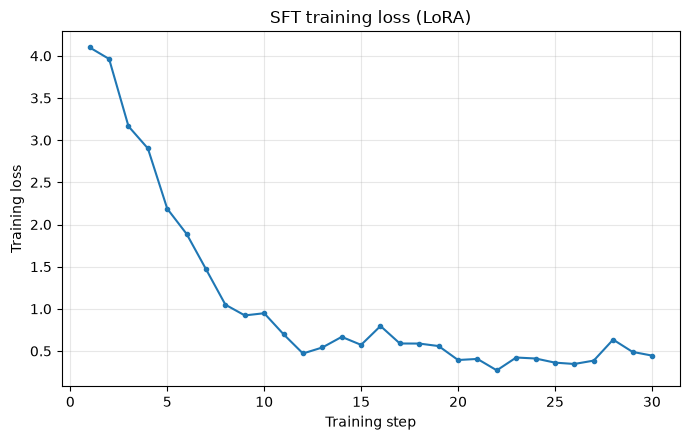

First logged loss: 4.0991   Last logged loss: 0.4461


In [ ]:
log = [r for r in trainer.state.log_history if "loss" in r]
steps = [r["step"] for r in log]
losses = [r["loss"] for r in log]

plt.figure(figsize=(7, 4.5))
plt.plot(steps, losses, marker="o", markersize=3)
plt.xlabel("Training step"); plt.ylabel("Training loss")
plt.title("SFT training loss (LoRA)"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("results/training_loss.png", dpi=150); plt.show()

print(f"First logged loss: {losses[0]:.4f}   Last logged loss: {losses[-1]:.4f}")

## 8. Compare the original model and the fine-tuned model
We ask the fine-tuned model the **same test questions** and put the answers next to the original model's answers.

In [12]:
model.config.use_cache = True
ft_answers = [ask(model, q) for _, q, _ in TEST_QUESTIONS]

def hit(answer, keywords):
    if not keywords:
        return None
    a = answer.lower()
    return any(k.lower() in a for k in keywords)

rows = []
for (group, q, kws), b, f in zip(TEST_QUESTIONS, base_answers, ft_answers):
    rows.append({"Group": group, "Question": q, "Original answer": b, "Fine-tuned answer": f,
                 "Original correct": hit(b, kws), "Fine-tuned correct": hit(f, kws)})
comparison = pd.DataFrame(rows)

for r in rows:
    print(f"[{r['Group']}] {r['Question']}")
    print(f"   ORIGINAL  : {r['Original answer']}")
    print(f"   FINE-TUNED: {r['Fine-tuned answer']}\n")

[A. Rephrased] How long is the warranty on a new laptop from your shop?
   ORIGINAL  : The warranty period for a new laptop typically ranges from 12 to 36 months depending on the model and country of purchase. It's important to check with your specific retailer or contact their customer service for the most accurate information.
   FINE-TUNED: A new laptop comes with a 2-year warranty.

[A. Rephrased] What time do you open on Sundays?
   ORIGINAL  : We don't have specific information about the opening hours of our shop on Sundays as it can vary depending on the location and business practices. However, we generally follow a standard 9-5 schedule for most shops. If you need to know the exact opening times, I recommend checking directly with the owner or visiting your local branch.
   FINE-TUNED: Sunday hours are 08:00 to 17:00.

[A. Rephrased] Is there a discount for students?
   ORIGINAL  : Yes, we offer a student discount on most items at our shop. Please let us know which products yo

In [13]:
scored = comparison.dropna(subset=["Original correct"]).copy()
summary = scored.groupby("Group")[["Original correct", "Fine-tuned correct"]].sum().astype(int)
summary["Questions"] = scored.groupby("Group").size()
summary.loc["Total"] = summary.sum()
display(summary)

score_total = summary.loc["Total"]
print(f"Keyword score: original {score_total['Original correct']}/{score_total['Questions']}  |  fine-tuned {score_total['Fine-tuned correct']}/{score_total['Questions']}")
print("Group C (not in training data) has no keywords: read the answers above to see whether the model invents facts.")

comparison.to_csv("results/comparison.csv", index=False)
summary.to_csv("results/score_summary.csv")
with open("results/comparison.md", "w", encoding="utf-8") as f:
    for r in rows:
        f.write(f"### [{r['Group']}] {r['Question']}\n\n- **Original:** {r['Original answer']}\n- **Fine-tuned:** {r['Fine-tuned answer']}\n\n")

,Original correct,Fine-tuned correct,Questions
Group,,,
A. Rephrased,0,1,6
B. New combination,0,1,3
D. General knowledge,2,2,2
Total,2,4,11


Keyword score: original 2/11  |  fine-tuned 4/11
Group C (not in training data) has no keywords: read the answers above to see whether the model invents facts.


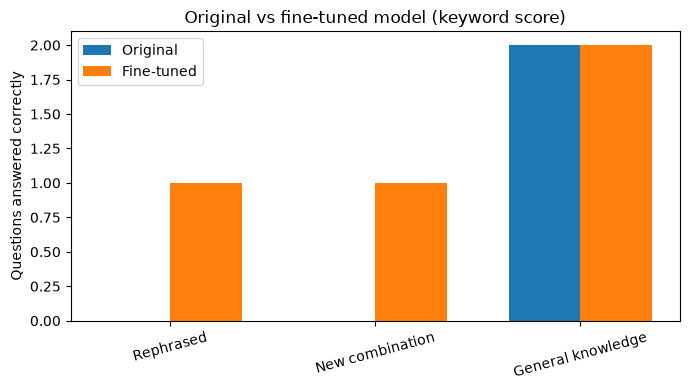

In [14]:
grp = summary.drop(index="Total")
x = np.arange(len(grp)); w = 0.35
plt.figure(figsize=(7, 4))
plt.bar(x - w/2, grp["Original correct"], w, label="Original")
plt.bar(x + w/2, grp["Fine-tuned correct"], w, label="Fine-tuned")
plt.xticks(x, [g.split(". ")[1] for g in grp.index], rotation=15)
plt.ylabel("Questions answered correctly"); plt.title("Original vs fine-tuned model (keyword score)")
plt.legend(); plt.tight_layout(); plt.savefig("results/score_comparison.png", dpi=150); plt.show()

## 9. Save the LoRA adapter and test reloading it
Only the small **adapter** is saved (not the whole model). To use it later, load the base model and attach the adapter.

In [15]:
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
size_mb = sum(os.path.getsize(os.path.join(ADAPTER_DIR, f)) for f in os.listdir(ADAPTER_DIR)) / 1e6
print("Saved adapter files:", sorted(os.listdir(ADAPTER_DIR)))
print(f"Adapter folder size: {size_mb:.1f} MB (the full base model is about {n_params_base*2/1e9:.1f} GB in 16-bit)")

metrics = {
    "model": MODEL_ID,
    "mode": "QLoRA (4-bit)" if use_qlora else "LoRA",
    "gpu": gpu_info.get("gpu_name", "none"),
    "gpu_memory_gb": gpu_info.get("gpu_memory_gb"),
    "lora_r": LORA_R, "lora_alpha": LORA_ALPHA, "lora_dropout": LORA_DROPOUT,
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE,
    "training_examples": len(QA_PAIRS), "training_steps": steps[-1] if steps else None,
    "trainable_parameters": n_trainable, "total_parameters": n_total,
    "trainable_percent": round(100 * n_trainable / n_total, 3),
    "first_loss": round(losses[0], 4), "last_loss": round(losses[-1], 4),
    "training_seconds": round(train_secs), "peak_gpu_memory_gb": round(peak_mem_gb, 2),
    "adapter_size_mb": round(size_mb, 1),
    "keyword_score_original": f"{int(score_total['Original correct'])}/{int(score_total['Questions'])}",
    "keyword_score_finetuned": f"{int(score_total['Fine-tuned correct'])}/{int(score_total['Questions'])}",
}
with open("results/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print(json.dumps(metrics, indent=2))

Saved adapter files: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json']
Adapter folder size: 46.7 MB (the full base model is about 1.0 GB in 16-bit)
{
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "mode": "LoRA",
  "gpu": "none",
  "gpu_memory_gb": null,
  "lora_r": 16,
  "lora_alpha": 32,
  "lora_dropout": 0.05,
  "epochs": 3,
  "learning_rate": 0.0002,
  "batch_size": 4,
  "training_examples": 40,
  "training_steps": 30,
  "trainable_parameters": 8798208,
  "total_parameters": 502830976,
  "trainable_percent": 1.75,
  "first_loss": 4.0991,
  "last_loss": 0.4461,
  "training_seconds": 315,
  "peak_gpu_memory_gb": 0.0,
  "adapter_size_mb": 46.7,
  "keyword_score_original": "2/11",
  "keyword_score_finetuned": "4/11"
}


In [16]:
# Reload: base model (plain 16-bit) + the saved adapter
from peft import PeftModel
del trainer, model
if HAS_CUDA:
    torch.cuda.empty_cache()

reloaded = PeftModel.from_pretrained(load_base_model(False), ADAPTER_DIR)
test_q = "Do you offer student discounts?"
print("Question :", test_q)
print("Reloaded fine-tuned model:", ask(reloaded, test_q))

Loading weights: 100%|██████████| 290/290 [00:02<00:00, 122.64it/s]


Question : Do you offer student discounts?
Reloaded fine-tuned model: Yes, students get 10% off purchases up to LKR 50,000.


## Download your results
Run this cell last. It zips the `results/` folder (plots, tables, metrics, dataset) and the small adapter so you can download them for your GitHub portfolio.

In [17]:
import shutil
shutil.make_archive("lab4_results", "zip", ".", "results")
shutil.make_archive("lab4_adapter", "zip", ".", ADAPTER_DIR)
print("Created lab4_results.zip with:", sorted(os.listdir("results")))
print("Created lab4_adapter.zip")
try:
    from google.colab import files
    files.download("lab4_results.zip"); files.download("lab4_adapter.zip")
except Exception as e:
    print("(Not running in Colab, skipping download):", e)

Created lab4_results.zip with: ['comparison.csv', 'comparison.md', 'gpu_info.json', 'metrics.json', 'score_comparison.png', 'score_summary.csv', 'training_dataset.json', 'training_loss.png']
Created lab4_adapter.zip
(Not running in Colab, skipping download): No module named 'google'


## Discussion
- **Why LoRA?** Full fine-tuning updates every weight and needs memory for gradients and optimizer states of the whole model. LoRA trains only a tiny fraction of the parameters (see the trainable-parameters percentage above), so it needs far less memory and produces a small adapter file.
- **Why QLoRA?** Storing the frozen base model in 4-bit cuts its memory by about four times, which lets larger models be fine-tuned on a small GPU, with only a small loss of quality.
- **What fine-tuning changed:** the model learned the shop-specific facts (prices, hours, policies) that it could not know before and answers in the short style of the training data.
- **Limits:** the dataset is tiny and synthetic. A fine-tuned model may still **invent** facts for questions it was never trained on (group C), and it can **forget** some general ability if trained too hard. Fine-tuning teaches style and facts seen in training; for facts that change often, retrieval (RAG, the next lab) is usually better.

## Notes for the README (fill in after running)
- Which GPU and how much memory did you have? Was QLoRA used?
- What fraction of the parameters was trained, and how long did training take?
- How did the training loss change?
- Which test questions did the fine-tuned model answer correctly that the original model got wrong?
- Did the fine-tuned model invent answers for questions not in the training data (group C)? Did it keep its general knowledge (group D)?